<a href="https://colab.research.google.com/github/Lorenzito/ProgramacionParaAnaliticaDescriptivayPredicitva/blob/main/Varela_Lorenzo_EDA_predictivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Lorenzo Varela Ollervides  

**Matrícula:** 273524

**Fecha:** 11 de octubre de 2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | Un contacto telefónico con un cliente durante la campaña de marketing directo del banco. |
| ¿Qué se predice? | `y`: si el cliente contrata el depósito a plazo (`yes`) o no (`no`). |
| ¿Qué tipo de problema es? | Clasificación binaria. |
| ¿En qué momento se haría la predicción y qué información existiría entonces? | Antes de llamar al cliente, para decidir a quién contactar. En ese momento se conocen sus datos personales y financieros (`age`, `job`, `marital`, `education`, `default`, `housing`, `loan`), su historial con campañas anteriores (`pdays`, `previous`, `poutcome`), los datos de la campaña actual (`contact`, `month`, `day_of_week`, `campaign`) y los indicadores económicos del periodo. No se conoce cuánto durará la llamada ni su resultado. |
| ¿Qué columnas no deberían usarse como características y por qué? | `duration`, porque la duración de la llamada solo se conoce cuando la llamada terminó, es decir, cuando ya se sabe si el cliente contrató; usarla sería fuga de información. Y `y`, que es la variable objetivo. |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito?

Espero que solo una minoría haya contratado, alrededor de 10% a 15%, porque en el telemarketing la mayoría de las llamadas no termina en una venta.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas?

No espero valores `NaN`, porque los faltantes de las categóricas se codifican con el texto `unknown`. Espero encontrar `unknown` en las columnas de datos personales y financieros: `job`, `marital`, `education`, `default`, `housing` y `loan`. En `job` y `marital` espero pocas filas (decenas o cientos); en `education` y sobre todo en `default` espero más, algunos miles, porque es información que el cliente puede no querer declarar.

In [2]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
#  - el tipo de dato de cada columna,
#  - el número de valores únicos por columna, de menor a mayor.

# Dimensiones: número de filas (contactos) y de columnas.
print("Dimensiones del conjunto:", df.shape)
print()

# info() muestra el tipo de dato de cada columna y cuántos valores no nulos tiene;
# sirve para detectar una columna numérica que se haya leído como texto.
df.info()
print()

# Valores únicos por columna, de menor a mayor: las columnas con pocos valores son
# categóricas y las que tienen muchos son numéricas continuas.
print("Valores únicos por columna:")
print(df.nunique().sort_values())

Dimensiones del conjunto: (41188, 21)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float

In [3]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
#  - ese conteo como porcentaje de las filas.

# Faltantes explícitos (NaN) en todo el conjunto.
print("Valores faltantes (NaN) en todo el conjunto:", df.isna().sum().sum())
print()

# En este conjunto los faltantes de las categóricas se codifican con el texto "unknown",
# que pandas no reconoce como NaN; se cuentan comparando cada columna con ese texto.
unknown = (df[categoricas] == "unknown").sum()
unknown = unknown[unknown > 0]  # solo las columnas con al menos un "unknown"

# Se muestra el conteo y su porcentaje respecto al total de filas.
faltantes = pd.DataFrame({
    "filas_unknown": unknown,
    "porcentaje": (unknown / df.shape[0] * 100).round(2),
}).sort_values("filas_unknown", ascending=False)
print("Filas con 'unknown' por columna categórica:")
print(faltantes)

Valores faltantes (NaN) en todo el conjunto: 0

Filas con 'unknown' por columna categórica:
           filas_unknown  porcentaje
default             8597       20.87
education           1731        4.20
housing              990        2.40
loan                 990        2.40
job                  330        0.80
marital               80        0.19


In [4]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.

# duplicated() marca las filas que repiten exactamente todos los valores de una fila anterior.
# El conjunto no tiene identificador de cliente, así que se comparan todas las columnas.
print("Filas completamente idénticas:", df.duplicated().sum())

Filas completamente idénticas: 12


In [5]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
#  - una tabla de contingencia entre poutcome y (previous == 0),
#  - una tabla de contingencia entre poutcome y (pdays == 999).
# Pista: pd.crosstab.

# pdays = 999 es un código especial: el cliente no fue contactado en una campaña anterior.
sin_contacto_previo = df["pdays"] == 999
print("Filas con pdays igual a 999:", sin_contacto_previo.sum())
print("Porcentaje de filas con pdays igual a 999:", round(sin_contacto_previo.mean() * 100, 2), "%")
print()

# Si las columnas son consistentes, poutcome = "nonexistent" debería coincidir con
# previous = 0 (sin contactos anteriores) y con pdays = 999 (nunca contactado antes).
print("poutcome frente a (previous == 0):")
print(pd.crosstab(df["poutcome"], df["previous"] == 0))
print()
print("poutcome frente a (pdays == 999):")
print(pd.crosstab(df["poutcome"], df["pdays"] == 999))

Filas con pdays igual a 999: 39673
Porcentaje de filas con pdays igual a 999: 96.32 %

poutcome frente a (previous == 0):
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

poutcome frente a (pdays == 999):
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [6]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
#  - cuántas llamadas tienen duration igual a 0,
#  - el mínimo y el máximo de campaign,
#  - cuántas filas tienen previous negativo.

# Criterios del dominio: no se calculan con los datos, solo se compara con lo que es posible.
print("Edad mínima:", df["age"].min(), "| Edad máxima:", df["age"].max())

# Una llamada de 0 segundos significa que no hubo conversación con el cliente.
print("Llamadas con duration igual a 0:", (df["duration"] == 0).sum())

# campaign incluye el último contacto, así que su mínimo posible es 1.
print("campaign mínimo:", df["campaign"].min(), "| campaign máximo:", df["campaign"].max())

# Un número de contactos anteriores no puede ser negativo.
print("Filas con previous negativo:", (df["previous"] < 0).sum())

Edad mínima: 17 | Edad máxima: 98
Llamadas con duration igual a 0: 4
campaign mínimo: 1 | campaign máximo: 56
Filas con previous negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable.

El conjunto tiene 41,188 filas y 21 columnas, y los tipos coinciden con el diccionario: 10 columnas numéricas (5 `int64` y 5 `float64`) y 11 de texto; ninguna columna numérica se leyó como texto. Los problemas encontrados son:

- **Faltantes.** No hay valores `NaN` (0), pero sí `unknown` en seis categóricas: `default` 8,597 filas (20.87%), `education` 1,731 (4.20%), `housing` 990 (2.40%), `loan` 990 (2.40%), `job` 330 (0.80%) y `marital` 80 (0.19%).
- **Duplicados.** Hay 12 filas completamente idénticas. Como el conjunto no tiene identificador, no se puede saber si son el mismo contacto registrado dos veces o clientes distintos con las mismas características.
- **Código especial en `pdays`.** 39,673 filas (96.32%) tienen `pdays` igual a 999, que no es un número de días sino el código de "no contactado antes".
- **Inconsistencia entre columnas.** `poutcome = nonexistent` coincide exactamente con `previous = 0` (35,563 filas en ambas tablas). Pero 4,110 filas con `poutcome = failure` tienen `pdays = 999`: según `poutcome` y `previous` el cliente sí fue contactado en una campaña anterior, pero según `pdays` no.
- **Rangos.** La edad va de 17 a 98 años y `previous` no tiene negativos (0), valores posibles. Hay 4 llamadas con `duration` igual a 0 y `campaign` va de 1 a 56 contactos.

Dependen del significado de la variable: los `unknown` (son faltantes aunque `pandas` no los cuente como `NaN`), el 999 de `pdays` (un código que, tratado como cantidad, sería un valor extremo), la inconsistencia de `pdays` con `poutcome`, las 4 llamadas de 0 segundos (llamadas en que no hubo conversación) y el máximo de 56 contactos de `campaign` (posible, pero extremo). Ninguno se detecta con el conteo de `NaN`.

Comparación con la predicción: acerté en que no habría `NaN` y en las seis columnas con `unknown`, así como en que `job` y `marital` tendrían pocas filas. Subestimé `default`: esperaba algunos miles y son 8,597, una de cada cinco filas.

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado.

La trataría como una categoría más. Eliminar las filas descartaría 8,597 contactos, el 20.87% del conjunto. Imputarla supondría asignar un valor (por ejemplo, `no`) a uno de cada cinco clientes sin saber si es correcto. Además, que el cliente no declare si tiene crédito en incumplimiento puede ser información en sí misma, y conservarla como categoría permite que el modelo la use.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué?

Sí, será prácticamente igual en los dos conjuntos, porque la división es estratificada según `y`: conserva la proporción de cada clase. Solo podría diferir en centésimas, porque el número de clientes de cada clase no siempre se divide exactamente en 80% y 20%.

In [7]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
#  - el porcentaje de contratación (y igual a yes) en cada uno.

# División 80/20 estratificada según y, para conservar la proporción de la clase minoritaria
# en ambos conjuntos; random_state=42 hace que la división sea reproducible.
entrenamiento, prueba = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=42)

print("Entrenamiento:", entrenamiento.shape, "| Prueba:", prueba.shape)
print("Contratación en entrenamiento:", round((entrenamiento["y"] == "yes").mean() * 100, 2), "%")
print("Contratación en prueba:", round((prueba["y"] == "yes").mean() * 100, 2), "%")

# ent es una copia de entrenamiento para explorar sin modificar el conjunto original.
# suscribe (1 = yes, 0 = no) permite calcular tasas de contratación como promedios.
ent = entrenamiento.copy()
ent["suscribe"] = (ent["y"] == "yes").astype(int)

Entrenamiento: (32950, 21) | Prueba: (8238, 21)
Contratación en entrenamiento: 11.27 %
Contratación en prueba: 11.26 %


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [8]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción.

La división dejó 32,950 contactos en entrenamiento y 8,238 en prueba, y la verificación se superó. La contratación es de 11.27% en entrenamiento y de 11.26% en prueba: difieren en una centésima, como predije, porque la estratificación conservó la proporción de la clase `yes` en ambos conjuntos.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría?

Obtendría una exactitud igual al porcentaje de clientes que no contratan. Como la contratación en entrenamiento fue de 11.27% (parte C), espero una exactitud cercana a 88.7%.

     clientes  porcentaje
y                        
no      29238       88.73
yes      3712       11.27

Razón entre clases (mayoritaria / minoritaria): 7.88
Exactitud de responder siempre no: 88.73 %


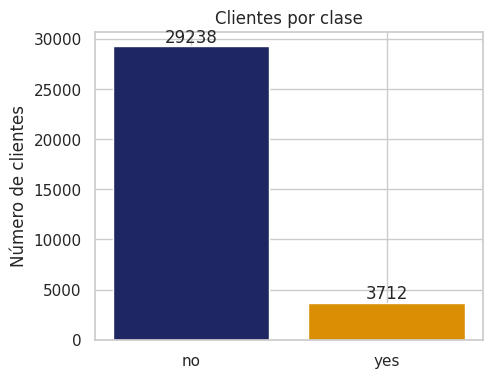

In [9]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
#  - la razón entre la clase mayoritaria y la minoritaria,
#  - la exactitud de responder siempre "no",
#  - una gráfica de barras con el número de clientes por clase.

# Conteo y porcentaje de cada clase de la variable objetivo.
conteo = ent["y"].value_counts()
porcentaje = (ent["y"].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({"clientes": conteo, "porcentaje": porcentaje}))
print()

# La razón entre clases mide el desbalance: cuántos "no" hay por cada "yes".
print("Razón entre clases (mayoritaria / minoritaria):", round(conteo["no"] / conteo["yes"], 2))

# Un modelo que siempre responde "no" acierta en todos los clientes que no contratan.
print("Exactitud de responder siempre no:", round((1 - ent["suscribe"].mean()) * 100, 2), "%")

# Gráfica de barras con el número de clientes por clase.
fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(conteo.index, conteo.values, color=conteo.index.map(COLORES_CLASE))
ax.bar_label(barras)
ax.set_title("Clientes por clase")
ax.set_ylabel("Número de clientes")
plt.show()

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo.

En `ent` hay 29,238 clientes `no` (88.73%) y 3,712 `yes` (11.27%); la razón entre clases es de 7.88, es decir, casi 8 clientes que no contratan por cada uno que contrata. Responder siempre `no` da una exactitud de 88.73%. Las dos predicciones se cumplieron: en la parte A esperaba entre 10% y 15% de contratación (fue 11.27%) y en la parte D una exactitud cercana a 88.7%.

Implicación: la clase que interesa detectar (`yes`) es la minoritaria y un modelo que nunca la detecta ya acierta el 88.73%. Por eso la exactitud no sirve como única métrica: hay que evaluar con métricas que miren la clase minoritaria, como la recuperación, la precisión, la puntuación F1 y el área bajo la curva. También implica usar particiones estratificadas en la validación cruzada y considerar técnicas para el desbalance de clases.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no?

Espero que `duration` sea la que más difiera: las llamadas en que el cliente contrata deberían durar más, porque hay que explicar el producto y cerrar la venta. También espero diferencias en los indicadores económicos, como `euribor3m` y `nr.employed`, si el contexto económico influye en la decisión de ahorrar. Espero diferencias pequeñas en `age` y `campaign`.

Mediana de las variables numéricas por clase de y:
      age  duration  campaign  pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
y                                                                                                                  
no   38.0     164.0       2.0  999.0       0.0           1.1           93.92          -41.8       4.86       5195.8
yes  37.0     448.0       2.0  999.0       0.0          -1.8           93.20          -40.4       1.27       5099.1


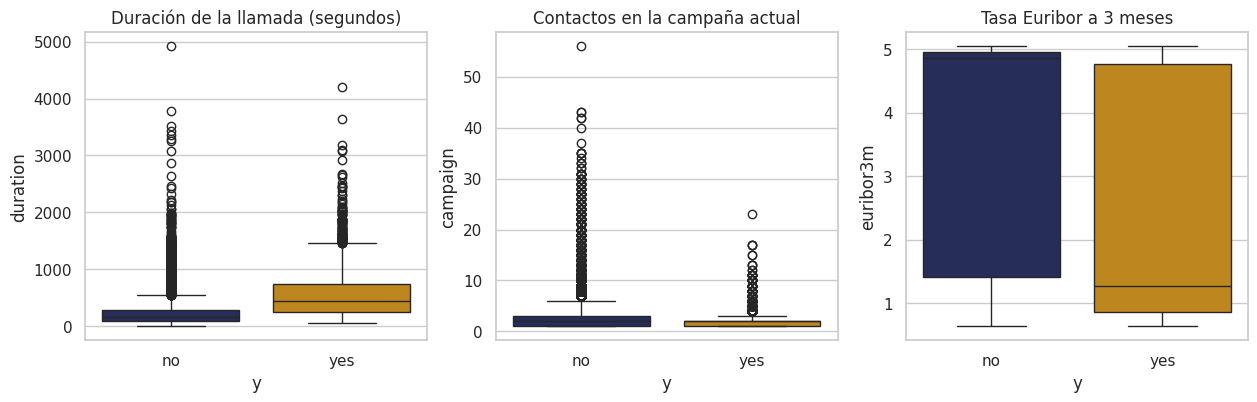

In [10]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.

# Mediana de cada variable numérica por clase; se usa la mediana porque es resistente a
# valores extremos.
print("Mediana de las variables numéricas por clase de y:")
print(ent.groupby("y")[numericas].median().round(2))

# Diagramas de caja por clase de tres variables: duration (duración de la llamada),
# campaign (contactos en la campaña actual) y euribor3m (indicador económico).
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=ent, x="y", y="duration", hue="y", order=["no", "yes"], palette=COLORES_CLASE, legend=False, ax=ejes[0])
sns.boxplot(data=ent, x="y", y="campaign", hue="y", order=["no", "yes"], palette=COLORES_CLASE, legend=False, ax=ejes[1])
sns.boxplot(data=ent, x="y", y="euribor3m", hue="y", order=["no", "yes"], palette=COLORES_CLASE, legend=False, ax=ejes[2])
ejes[0].set_title("Duración de la llamada (segundos)")
ejes[1].set_title("Contactos en la campaña actual")
ejes[2].set_title("Tasa Euribor a 3 meses")
plt.show()

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas.

**Separan las clases:**

- `duration`: mediana de 448 segundos en quienes contratan frente a 164 en quienes no, casi el triple. En el diagrama de caja, la caja de `yes` queda por encima de la de `no`.
- `euribor3m`: 1.27 en quienes contratan frente a 4.86 en quienes no. En el diagrama de caja la mediana de `no` está cerca del máximo, aunque las cajas de las dos clases se traslapan.
- `emp.var.rate`: −1.8 frente a 1.1, y `nr.employed`: 5,099.1 frente a 5,195.8. Quienes contratan lo hicieron en periodos con valores más bajos de estos indicadores.

**Separan poco:** `cons.price.idx` (93.20 frente a 93.92) y `cons.conf.idx` (−40.4 frente a −41.8).

**No separan según la mediana:** `age` (37 frente a 38), `campaign` (2 en ambas clases), `pdays` (999 en ambas) y `previous` (0 en ambas). En `pdays` y `previous` la mediana no puede mostrar diferencias, porque el 96.32% de las filas tiene `pdays` igual a 999 (B4). En `campaign` la mediana es igual, pero el diagrama de caja muestra que la cola de `no` llega hasta 56 contactos, mientras que en `yes` no pasa de unos 23.

Comparación con la predicción: acerté en `duration`, que es la que más difiere, y en los indicadores `euribor3m` y `nr.employed`; también en que `age` y `campaign` casi no difieren. No había anticipado la diferencia de `emp.var.rate`.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey?

Espero más registros fuera de los límites en `duration` y `campaign`, que tienen colas largas hacia la derecha (en B5 `campaign` llega a 56 contactos y en D2 los diagramas de caja de ambas muestran muchos puntos por encima de la caja). También en `pdays` y `previous`: como el 96.32% de las filas tiene `pdays` igual a 999 (B4) y la mediana de `previous` es 0 (D2), sus cuartiles serán iguales y cualquier otro valor quedará fuera. En los indicadores económicos espero pocos o ninguno.

In [11]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.

# Los cuartiles se calculan solo con entrenamiento (ent), porque son parámetros obtenidos de los datos.
q1 = ent[numericas].quantile(0.25)
q3 = ent[numericas].quantile(0.75)
ric = q3 - q1

# Límites de Tukey: 1.5 veces el rango intercuartílico por debajo de Q1 y por encima de Q3.
inferior = q1 - 1.5 * ric
superior = q3 + 1.5 * ric

# Tabla con los límites y el número de registros fuera de ellos por variable.
atipicos = pd.DataFrame({
    "limite_inferior": inferior,
    "limite_superior": superior,
    "fuera_de_limites": ((ent[numericas] < inferior) | (ent[numericas] > superior)).sum(),
})
print("Límites de Tukey (1.5 RIC) y registros fuera de ellos, por variable:")
print(atipicos.round(2))

Límites de Tukey (1.5 RIC) y registros fuera de ellos, por variable:
                limite_inferior  limite_superior  fuera_de_limites
age                        9.50            69.50               368
duration                -221.00           643.00              2366
campaign                  -2.00             6.00              1916
pdays                    999.00           999.00              1226
previous                   0.00             0.00              4534
emp.var.rate              -6.60             6.20                 0
cons.price.idx            91.70            95.37                 0
cons.conf.idx            -52.15           -26.95               359
euribor3m                 -4.08            10.39                 0
nr.employed             4905.60          5421.60                 0


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado.

No eliminaría los registros atípicos de ninguna variable, porque en todas son valores posibles:

- `age`: 368 registros por encima de 69.5 años. Son clientes mayores reales (la edad máxima es 98, B5), y en el diccionario no hay nada que los haga imposibles.
- `duration`: 2,366 llamadas de más de 643 segundos. Son llamadas largas reales; además, la variable no se usará como característica (parte A).
- `campaign`: 1,916 registros con más de 6 contactos. Son clientes a los que se llamó muchas veces; si se usa un modelo sensible a valores extremos, conviene reducir el efecto de la cola sin eliminar registros.
- `pdays`: 1,226 registros fuera. Los límites son 999 y 999 porque casi todas las filas tienen el código 999, así que "fuera" significa "contactado en una campaña anterior". Eliminarlos quitaría justamente a los clientes con historial previo.
- `previous`: 4,534 registros fuera, por la misma razón: los límites son 0 y 0, y los registros fuera son los clientes con contactos anteriores.
- `cons.conf.idx`: 359 registros por debajo de −52.15. Es un indicador económico del periodo, no un dato capturado por cliente; los valores bajos corresponden a meses reales.
- `emp.var.rate`, `cons.price.idx`, `euribor3m` y `nr.employed` no tienen registros fuera de los límites.

La decisión depende del modelo: los árboles de decisión y sus conjuntos no son sensibles a estos valores; para modelos lineales, máquinas de soporte vectorial o redes neuronales se trata la escala y la cola, no se eliminan registros.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`?

El logaritmo, porque `campaign` tiene una cola muy larga a la derecha (va de 1 a 56 contactos en B5 y tiene 1,916 registros por encima del límite superior de Tukey en D3), y el logaritmo comprime más los valores grandes que la raíz cuadrada.

          original  raiz_cuadrada  logaritmo
age           0.76           0.43       0.13
duration      3.33           1.20      -0.43
campaign      4.74           2.16       1.35


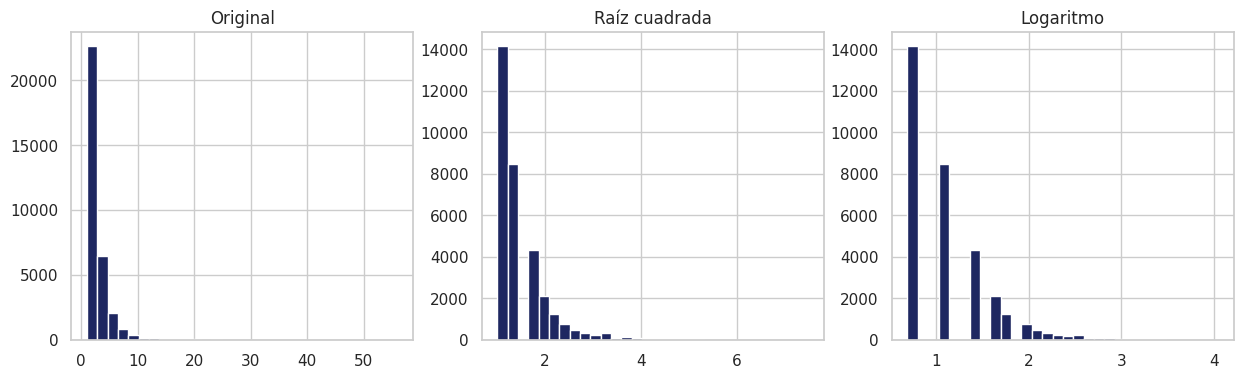

In [12]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.

variables = ["age", "duration", "campaign"]

# Asimetría de cada variable sin transformar y con cada transformación monótona.
# np.log1p calcula log(1 + x), por lo que admite el valor 0 de duration.
comparacion = pd.DataFrame({
    "original": ent[variables].skew(),
    "raiz_cuadrada": np.sqrt(ent[variables]).skew(),
    "logaritmo": np.log1p(ent[variables]).skew(),
}).round(2)
print(comparacion)

# Histogramas de campaign: original y con cada transformación, para ver cómo cambia la forma.
variable = "campaign"
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].hist(ent[variable], bins=30, color=AZUL, edgecolor="white")
ejes[0].set_title("Original")
ejes[1].hist(np.sqrt(ent[variable]), bins=30, color=AZUL, edgecolor="white")
ejes[1].set_title("Raíz cuadrada")
ejes[2].hist(np.log1p(ent[variable]), bins=30, color=AZUL, edgecolor="white")
ejes[2].set_title("Logaritmo")
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable.

| Variable | Original | Raíz cuadrada | Logaritmo |
| --- | --- | --- | --- |
| `age` | 0.76 | 0.43 | 0.13 |
| `duration` | 3.33 | 1.20 | −0.43 |
| `campaign` | 4.74 | 2.16 | 1.35 |

- `campaign`: es la más asimétrica (4.74). El logaritmo la reduce más (1.35) que la raíz cuadrada (2.16), como predije. Aun así sigue asimétrica: en el histograma transformado la mayoría de los registros sigue en las primeras barras, porque la variable toma pocos valores enteros y casi todos son bajos. Para modelos sensibles a la escala aplicaría el logaritmo; para árboles, ninguna transformación.
- `age`: asimetría moderada (0.76). El logaritmo la deja casi simétrica (0.13) y la raíz cuadrada en 0.43. Aplicaría el logaritmo solo para modelos sensibles a la escala.
- `duration`: muy asimétrica (3.33). El logaritmo la lleva a −0.43, más cerca de 0 que la raíz cuadrada (1.20), aunque la cola pasa al lado izquierdo. No aplicaría ninguna, porque la variable no se usará como característica (parte A).

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases?

Espero que `poutcome` tenga la categoría con mayor tasa: los clientes que ya contrataron en una campaña anterior (`success`) deberían volver a hacerlo. Espero que casi no separen las clases `day_of_week`, `housing` y `loan`, porque el día de la llamada o tener un crédito no deberían cambiar mucho la decisión de abrir un depósito.

In [13]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
#  - la tasa global de contratación en ent.

# Número de categorías por variable (incluye "unknown" donde aparece).
print("Número de categorías por característica:")
print(ent[categoricas].nunique().sort_values())
print()

# La tasa global es la referencia contra la que se compara la tasa de cada categoría.
print("Tasa global de contratación:", round(ent["suscribe"].mean() * 100, 2), "%")

Número de categorías por característica:
contact         2
default         3
housing         3
loan            3
poutcome        3
marital         4
day_of_week     5
education       8
month          10
job            12
dtype: int64

Tasa global de contratación: 11.27 %


In [14]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
#  - las 12 categorías con mayor tasa,
#  - las 8 con menor tasa,
#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.

# melt pasa las columnas categóricas a formato largo: una fila por (característica, categoría),
# con la columna suscribe al lado, para agrupar todas las variables en una sola operación.
largo = ent[categoricas].astype(str).assign(suscribe=ent["suscribe"]).melt(
    id_vars="suscribe", var_name="caracteristica", value_name="categoria"
)

# Por cada categoría: número de clientes y tasa de contratación (promedio de suscribe).
tasas = largo.groupby(["caracteristica", "categoria"])["suscribe"].agg(clientes="count", tasa_contratacion="mean")
tasas["tasa_contratacion"] = (tasas["tasa_contratacion"] * 100).round(1)

print("Categorías con mayor tasa de contratación:")
print(tasas.sort_values("tasa_contratacion", ascending=False).head(12))
print()
print("Categorías con menor tasa de contratación:")
print(tasas.sort_values("tasa_contratacion", ascending=False).tail(8))

# Tablas de las variables que se revisan por separado.
for variable in ["default", "housing", "loan", "day_of_week"]:
    print()
    print("Tasa de contratación según", variable + ":")
    print(tasas.loc[variable])

Categorías con mayor tasa de contratación:
                           clientes  tasa_contratacion
caracteristica categoria                              
poutcome       success         1105               64.9
month          dec              143               50.3
               mar              436               49.8
               sep              464               44.6
               oct              587               43.3
job            student          711               30.5
               retired         1366               25.5
month          apr             2085               20.5
education      illiterate        16               18.8
marital        unknown           65               16.9
education      unknown         1397               14.8
contact        cellular       20908               14.7

Categorías con menor tasa de contratación:
                            clientes  tasa_contratacion
caracteristica categoria                               
education      basic.6y        

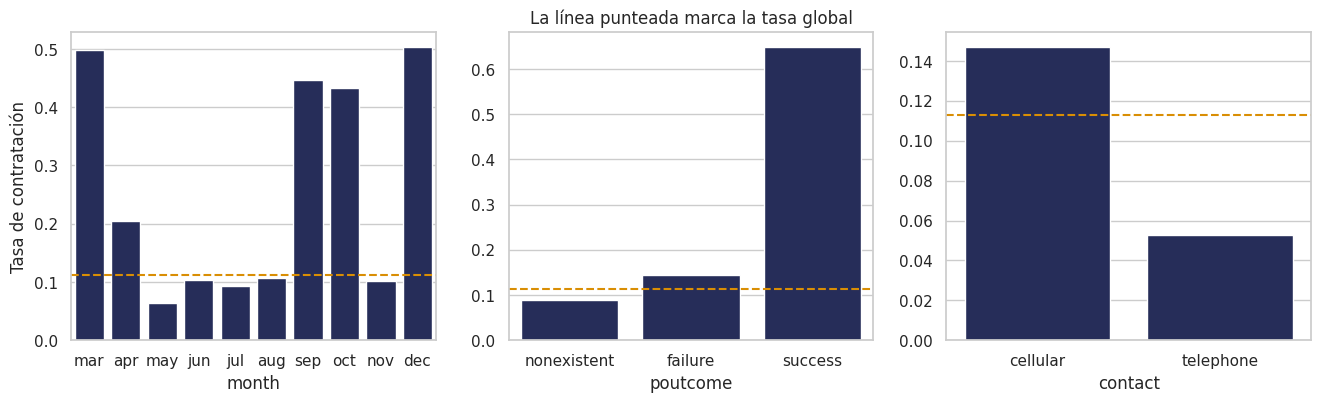

In [15]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.

# barplot calcula el promedio de suscribe por categoría, es decir, la tasa de contratación.
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=ent, x="month", y="suscribe",
            order=["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"],
            color=AZUL, errorbar=None, ax=ejes[0])
sns.barplot(data=ent, x="poutcome", y="suscribe", color=AZUL, errorbar=None, ax=ejes[1])
sns.barplot(data=ent, x="contact", y="suscribe", color=AZUL, errorbar=None, ax=ejes[2])

# Línea punteada en la tasa global, para ver qué categorías quedan por encima o por debajo.
ejes[0].axhline(ent["suscribe"].mean(), color=NARANJA, linestyle="--")
ejes[1].axhline(ent["suscribe"].mean(), color=NARANJA, linestyle="--")
ejes[2].axhline(ent["suscribe"].mean(), color=NARANJA, linestyle="--")
ejes[0].set_ylabel("Tasa de contratación")
ejes[1].set_ylabel("")
ejes[2].set_ylabel("")
ejes[1].set_title("La línea punteada marca la tasa global")
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases.

La tasa global de contratación es de 11.27%.

**Mayor tasa.** `poutcome = success` tiene la tasa más alta: 64.9% con 1,105 clientes. Le siguen cuatro meses: diciembre (50.3%, 143 clientes), marzo (49.8%, 436), septiembre (44.6%, 464) y octubre (43.3%, 587); en la gráfica los cuatro quedan muy por encima de la línea de la tasa global. Son meses con pocos contactos: mayo, en cambio, tiene 11,011 clientes. Después aparecen `job = student` (30.5%, 711) y `job = retired` (25.5%, 1,366).

**Menor tasa.** `default = yes` tiene 0.0%, pero con solo 3 clientes. Le siguen `default = unknown` (5.2%, 6,940), `contact = telephone` (5.3%, 12,042), `month = may` (6.3%, 11,011) y `job = blue-collar` (6.9%, 7,441). En `contact`, el celular tiene 14.7% (20,908 clientes), por encima de la tasa global, y el teléfono fijo queda por debajo. En la gráfica de `poutcome`, `failure` queda ligeramente por encima de la línea global y `nonexistent` por debajo.

**Casi no separan las clases:** `housing` (10.9%, 11.3% y 11.6%), `loan` (11.3%, 11.3% y 11.2%) y `day_of_week` (de 10.2% el lunes a 12.0% el jueves). Todas sus categorías quedan a 1.1 puntos porcentuales o menos de la tasa global.

Comparación con la predicción: acerté en que `poutcome = success` tendría la mayor tasa y en que `housing`, `loan` y `day_of_week` casi no separan las clases. No anticipé que `month` tuviera tantas categorías con tasas altas ni la diferencia de `contact`.

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`?

En `default`, los clientes `unknown` contratan el 5.2% (6,940 clientes) y los `no` el 12.9% (26,007). Eso indica que el faltante no es aleatorio: no declarar la información se asocia con una menor contratación, así que `unknown` contiene información para el modelo. Refuerza la decisión de tratarla como una categoría más (parte B) en lugar de imputarla con `no`, que mezclaría dos grupos con tasas distintas.

Con `default = yes` y `education = illiterate` hay que cuidar el número de clientes. `default = yes` tiene 3 clientes y una tasa de 0.0%; `illiterate` tiene 16 clientes y 18.8%. Son tasas calculadas con muy pocos registros y no son confiables: un cliente más o uno menos las cambia mucho. Un modelo podría aprender una regla a partir de esos pocos casos que no se repita en datos nuevos. No hay que interpretarlas como evidencia y conviene agruparlas con otra categoría al codificar.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados?

Espero que `euribor3m`, `emp.var.rate` y `nr.employed` estén muy correlacionados entre sí, porque los tres siguen el ciclo económico y en D2 se movieron en la misma dirección entre las clases. Espero que `cons.conf.idx` tenga una correlación más baja con los demás.

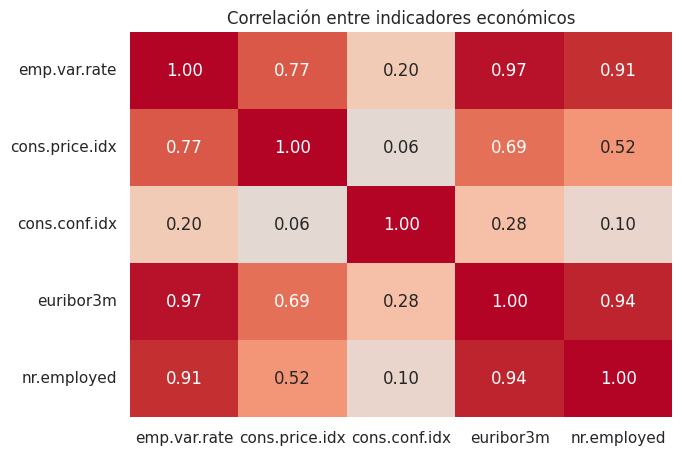

In [16]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.

# Matriz de correlación de los indicadores económicos, solo con entrenamiento; annot=True escribe
# el valor en cada celda y vmin/vmax fijan la escala de -1 a 1.
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(ent[macro].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=False, ax=ax)
ax.set_title("Correlación entre indicadores económicos")
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican.

Los pares más correlacionados son `emp.var.rate` y `euribor3m` (0.97), `euribor3m` y `nr.employed` (0.94) y `emp.var.rate` y `nr.employed` (0.91). Siguen `emp.var.rate` y `cons.price.idx` (0.77) y `euribor3m` y `cons.price.idx` (0.69). `cons.conf.idx` es el menos relacionado con los demás (de 0.06 a 0.28). Coincide con mi predicción.

Decisión: `emp.var.rate`, `euribor3m` y `nr.employed` son casi redundantes y causarían colinealidad en un modelo lineal. Para modelos lineales conservaría solo una de las tres (por ejemplo, `euribor3m`) y confirmaría con validación cruzada que no se pierde desempeño; los árboles de decisión toleran la redundancia, así que con ellos pueden conservarse.

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [17]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.

# Resumen estadístico de la duración de la llamada (en segundos) para cada clase.
print(ent.groupby("y")["duration"].describe().round(1))

       count   mean    std   min    25%    50%    75%     max
y                                                            
no   29238.0  221.1  208.3   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.4  397.5  63.0  252.0  448.0  737.0  4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado.

No. `duration` es la duración de la última llamada, en segundos: solo se conoce cuando la llamada terminó, y para entonces ya se sabe si el cliente contrató. Un modelo que decide a quién llamar se usa antes de la llamada, cuando ese dato no existe. Lo observado muestra por qué sería engañoso incluirla: quienes contratan tienen una mediana de 448 segundos frente a 164 de quienes no, y una media de 549.4 frente a 221.1; además, ninguna llamada con contratación duró menos de 63 segundos. Esa separación tan fuerte haría que el modelo pareciera muy bueno en la evaluación, pero esa información no estará disponible al predecir. Es fuga de información.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras?

Al dividir al azar, entrenamiento y prueba contienen contactos de los mismos meses, con los mismos valores de los indicadores económicos. Los indicadores toman pocos valores distintos que se repiten en miles de contactos (10 en `emp.var.rate` y 11 en `nr.employed`, B1), así que el modelo puede aprender a reconocer el periodo y la tasa de contratación de ese periodo, que varía mucho por mes (de 6.3% en mayo a 50.3% en diciembre, E2). En la evaluación, el modelo ya habrá visto esas condiciones, y el desempeño será optimista. En una campaña futura las condiciones económicas pueden ser distintas a todas las del conjunto, y el modelo rendiría peor. Para estimar el desempeño en campañas futuras convendría evaluar con contactos posteriores a los de entrenamiento, es decir, dividir según la fecha.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
| `duration` solo se conoce al terminar la llamada; mediana de 448 s en `yes` frente a 164 s en `no` | Excluirla de las características del modelo (fuga de información) | Preprocesamiento |
| `unknown` en `default` en 8,597 filas (20.87%), con tasa en entrenamiento de 5.2% frente a 12.9% de `no`; también en `education` (1,731), `housing` y `loan` (990), `job` (330) y `marital` (80) | Conservar `unknown` como una categoría más; no eliminar filas ni imputar | Preprocesamiento |
| `pdays` igual a 999 en 39,673 filas (96.32%), código de "no contactado antes"; 4,110 filas con `poutcome = failure` y `pdays = 999` | No tratar 999 como cantidad: representar "no contactado antes" como categoría o indicador, y revisar la inconsistencia con `poutcome` y `previous` | Preprocesamiento |
| La clase `yes` es el 11.27%; razón entre clases de 7.88; responder siempre `no` acierta el 88.73% | Partición estratificada; evaluar con recuperación, precisión, F1 y área bajo la curva; considerar sobremuestreo o ponderación de clases | Preprocesamiento y evaluación |
| Correlación de 0.97 entre `emp.var.rate` y `euribor3m`, 0.94 entre `euribor3m` y `nr.employed` y 0.91 entre `emp.var.rate` y `nr.employed` | Para modelos lineales conservar solo uno de los tres indicadores; con árboles pueden conservarse | Preprocesamiento y modelos |
| Asimetría de `campaign` de 4.74 (1.35 con logaritmo) y de `age` de 0.76 (0.13 con logaritmo) | Aplicar `np.log1p` a `campaign` y `age` solo para modelos sensibles a la escala; ninguna transformación con árboles | Preprocesamiento y modelos |
| Registros fuera de los límites de Tukey: 1,916 en `campaign`, 368 en `age`, 359 en `cons.conf.idx`; todos son valores posibles | No eliminarlos; la decisión depende del modelo | Preprocesamiento y modelos |
| `poutcome = success` (64.9%, 1,105 clientes), `contact = telephone` (5.3%, 12,042) y `month = may` (6.3%, 11,011) se alejan de la tasa global de 11.27%; `housing`, `loan` y `day_of_week` quedan entre 10.2% y 12.0% | Priorizar `poutcome`, `month` y `contact`; considerar descartar `housing`, `loan` y `day_of_week`, confirmándolo con validación cruzada | Preprocesamiento y evaluación |
| `default = yes` tiene 3 clientes (0.0%) y `education = illiterate` 16 clientes (18.8%) | No interpretar sus tasas; agruparlas con otra categoría al codificar | Preprocesamiento |
| Datos ordenados por fecha; indicadores con pocos valores (10 en `emp.var.rate`, 11 en `nr.employed`) y tasa por mes de 6.3% a 50.3% | Para estimar el desempeño en campañas futuras, evaluar con contactos posteriores a los de entrenamiento | Evaluación |
| El conjunto de prueba (8,238 contactos) no se exploró | Usarlo una sola vez, para la evaluación final | Evaluación |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio.

Con el conjunto total `df` se hizo la parte B: estructura (dimensiones, tipos y valores únicos), faltantes y `unknown`, duplicados, consistencia entre `pdays`, `previous` y `poutcome`, y rangos según el dominio. En la parte C se dividió `df` en entrenamiento y prueba. Las partes D, E y F se hicieron solo con `ent`, la copia de entrenamiento: distribución del objetivo, medianas por clase, límites de Tukey, asimetría, tasas por categoría, correlaciones entre indicadores y el resumen de `duration` por clase.

El criterio es si el análisis puede cambiar cómo se prepara, selecciona o transforma la información para el modelo. La parte B solo describe y detecta problemas con criterios estructurales o del dominio (por ejemplo, que `previous` no puede ser negativo): no usa la variable objetivo ni calcula parámetros que se apliquen al modelo. Las partes D a F relacionan las características con `y` o calculan parámetros a partir de los datos (cuartiles, asimetrías, correlaciones), y de ellos salen decisiones de modelado; por eso se hicieron solo con entrenamiento.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final?

La decisión de qué variables categóricas priorizar y cuáles descartar. Se tomó con las tasas por categoría, y varias se calcularon con pocos clientes (diciembre, 50.3% con 143 clientes; marzo, 49.8% con 436). Si esas tasas incluyeran los contactos de prueba, la selección de variables ya se habría ajustado a los mismos datos con los que después se evalúa el modelo. En la evaluación final, el modelo acertaría en prueba en parte porque las variables se eligieron mirando esos datos, y el desempeño reportado sería optimista: más alto que el que tendría en una campaña nueva. Lo mismo pasaría con los límites de Tukey, la transformación de `campaign` o la elección de un solo indicador económico, si se hubieran calculado con prueba.